# Neoadjuvant Response: EDA + unsupervised hypothesis notebook

Poking around the data before committing to a modeling approach for **Neoadjuvant Response**. Mostly checking data quality, how responders and non-responders differ, whether there's any latent cluster structure worth exploiting, and what hypotheses that suggests for the models that come next.

In [16]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_mutual_info_score

sns.set(style='whitegrid', context='talk')
RANDOM_STATE = 42

In [17]:
# Load data
data_path = 'data.csv'
df = pd.read_csv(data_path)

target_col = 'Neoadjuvant Response'
id_col = 'PERSON_ID'

df = df.drop('Unnamed: 0', axis=1)

print(f'Shape: {df.shape}')
print(f'Columns: {len(df.columns)}')
df.head()

Shape: (1430, 28)
Columns: 28


,PERSON_ID,Neoadjuvant Response,Age,Ki67 positive cells (%) at CB,N (Regional nodes affected),Side location of the lesion,Source of referral,Type of invasion at CB,Progesterone receptor status at CB,Grade at CB,...,Classification with respect to other lesions_2.0,Classification with respect to other lesions_3.0,Isotype at CB_1.0,Isotype at CB_2.0,Isotype at CB_3.0,Isotype at CB_4.0,Isotype at CB_nan,Disease extent_0.0,Disease extent_1.0,Disease extent_2.0
0,8,1,55.0,40.0,0.0,0.0,0,1.0,1.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,9,1,34.0,40.0,1.0,1.0,1,1.0,1.0,3.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,24,1,50.0,30.0,0.0,1.0,1,1.0,0.0,2.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,29,1,45.0,40.0,0.0,0.0,1,1.0,1.0,2.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,37,1,57.0,80.0,2.0,1.0,1,1.0,0.0,3.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [18]:
# Basic structure and data quality
display(df.describe(include='all').T.head(15))

missing = df.isna().mean().sort_values(ascending=False)
missing_nonzero = missing[missing > 0]

print('Columns with missing values:', len(missing_nonzero))
if len(missing_nonzero) > 0:
    display((missing_nonzero * 100).round(2).rename('missing_%').to_frame().head(20))

,count,mean,std,min,25%,50%,75%,max
PERSON_ID,1430.0,1897.204196,929.115500,8.0,1165.25,1961.0,2672.75,3479.0
Neoadjuvant Response,1430.0,0.697203,0.459629,0.0,0.00,1.0,1.00,1.0
Age,1430.0,53.517483,12.816820,20.0,44.00,52.0,63.00,91.0
Ki67 positive cells (%) at CB,1430.0,44.116084,22.718078,1.0,30.00,40.0,60.00,100.0
N (Regional nodes affected),1430.0,0.528671,0.666254,0.0,0.00,0.0,1.00,3.0
Side location of the lesion,1430.0,0.487413,0.500016,0.0,0.00,0.0,1.00,1.0
Source of referral,1430.0,0.406993,0.491445,0.0,0.00,0.0,1.00,1.0
Type of invasion at CB,1430.0,0.986713,0.114540,0.0,1.00,1.0,1.00,1.0
Progesterone receptor status at CB,1430.0,0.668531,0.470906,0.0,0.00,1.0,1.00,1.0
Grade at CB,1430.0,2.309790,0.553482,1.0,2.00,2.0,3.00,3.0


Columns with missing values: 0


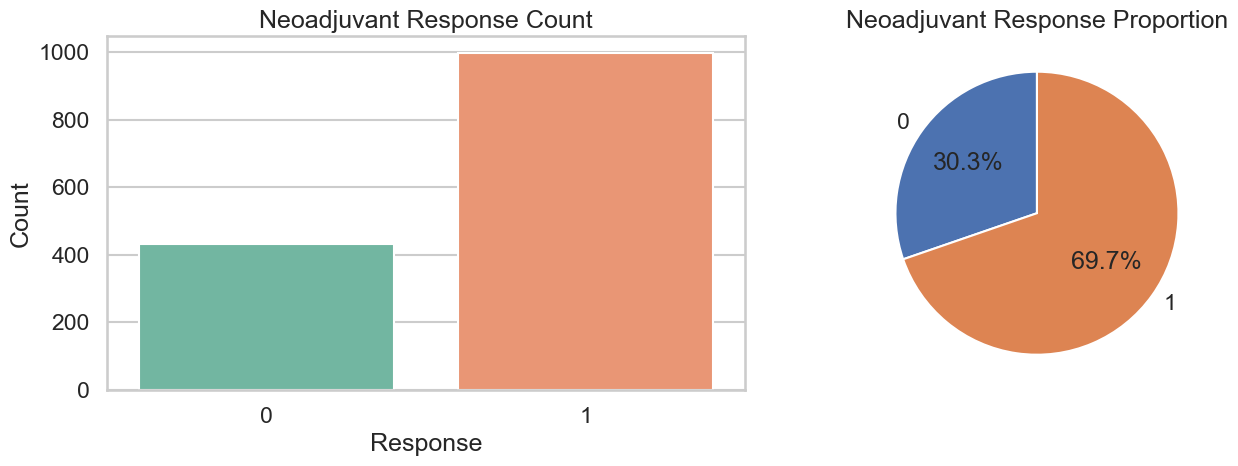

,count,percent
Neoadjuvant Response,,
0,433,30.28
1,997,69.72


In [19]:
# Target distribution
response_counts = df[target_col].value_counts().sort_index()
response_pct = (response_counts / response_counts.sum() * 100).round(2)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=response_counts.index, y=response_counts.values, ax=ax[0], palette='Set2')
ax[0].set_title('Neoadjuvant Response Count')
ax[0].set_xlabel('Response')
ax[0].set_ylabel('Count')

ax[1].pie(response_counts.values, labels=[f'{k}' for k in response_counts.index], autopct='%1.1f%%', startangle=90)
ax[1].set_title('Neoadjuvant Response Proportion')

plt.tight_layout()
plt.show()

display(pd.DataFrame({'count': response_counts, 'percent': response_pct}))

Numeric columns considered: 26


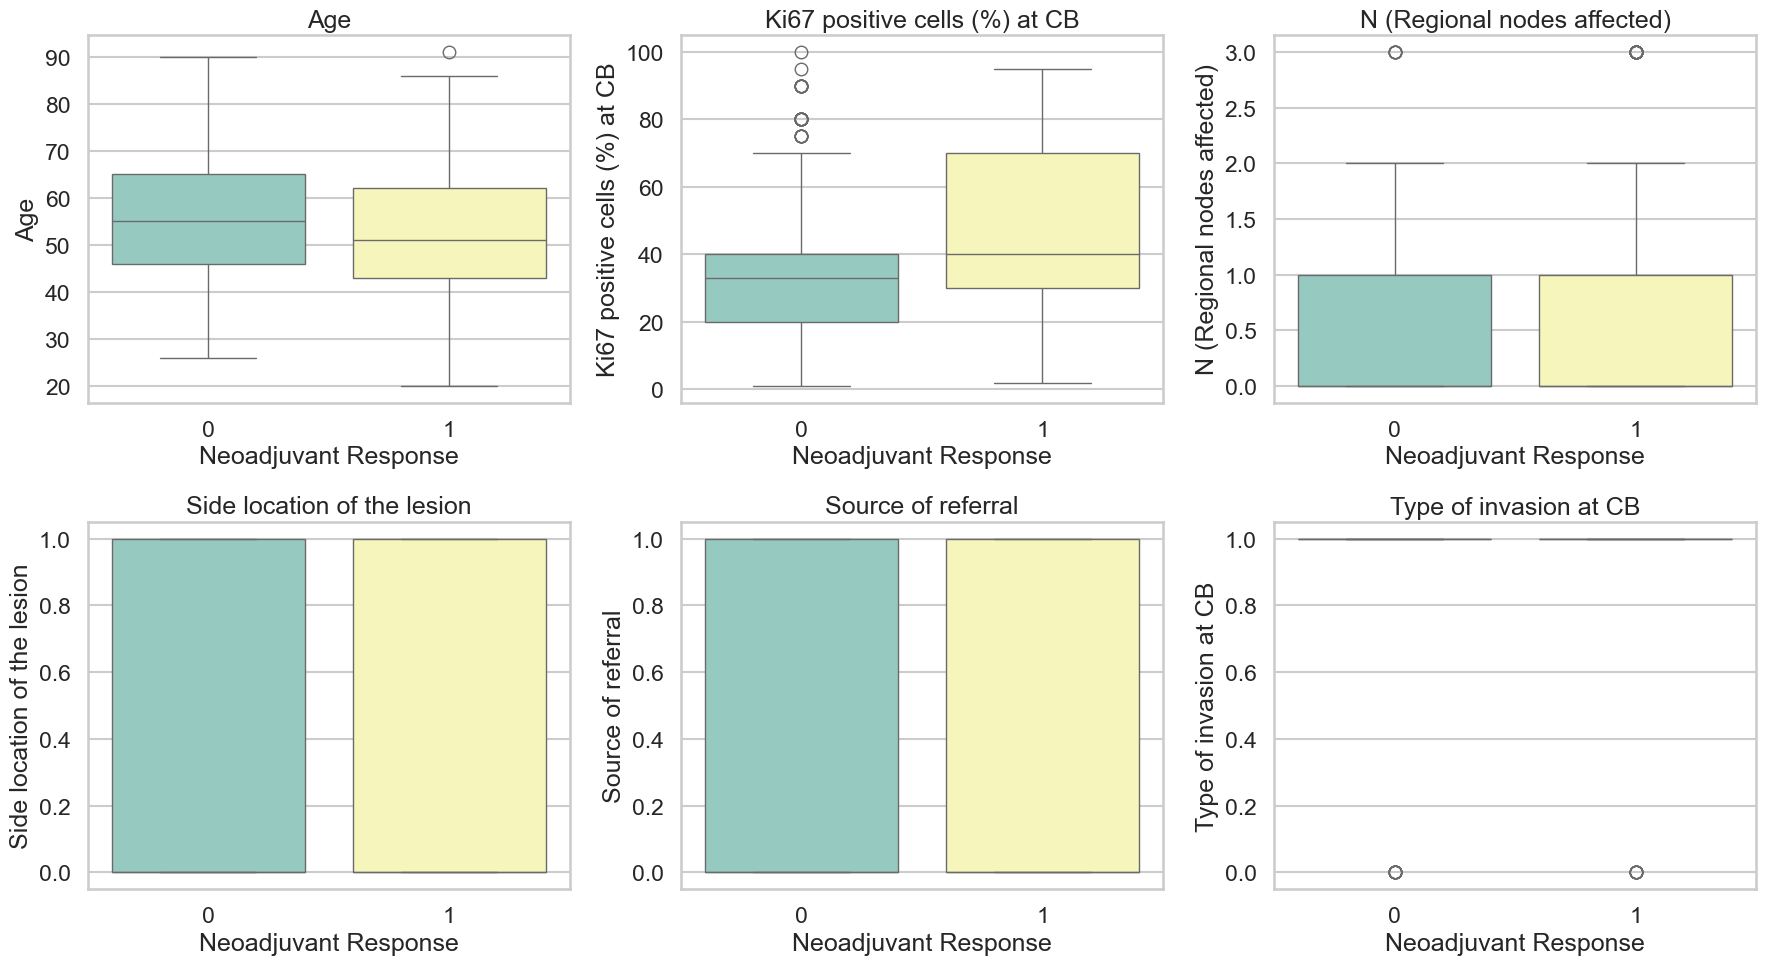

In [20]:
# Compare numeric features by response
excluded = {target_col, id_col}
feature_cols = [c for c in df.columns if c not in excluded]
numeric_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(df[c])]

print(f'Numeric columns considered: {len(numeric_cols)}')

if len(numeric_cols) > 0:
    n_show = min(6, len(numeric_cols))
    show_cols = numeric_cols[:n_show]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, col in enumerate(show_cols):
        sns.boxplot(data=df, x=target_col, y=col, ax=axes[i], palette='Set3')
        axes[i].set_title(col)

    for j in range(len(show_cols), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

,corr_with_response
Ki67 positive cells (%) at CB,0.244900
Grade at CB,0.236951
Her2 overexpression (with immunohystochemistry) at CB_3.0,0.229349
Progesterone receptor status at CB,-0.228021
Isotype at CB_1.0,0.198949
Oestrogen receptor status at CB_0.0,0.188411
Isotype at CB_2.0,-0.178133
Her2 overexpression (with immunohystochemistry) at CB_1.0,-0.170405
Oestrogen receptor status at CB_1.0,-0.168347
Age,-0.111654


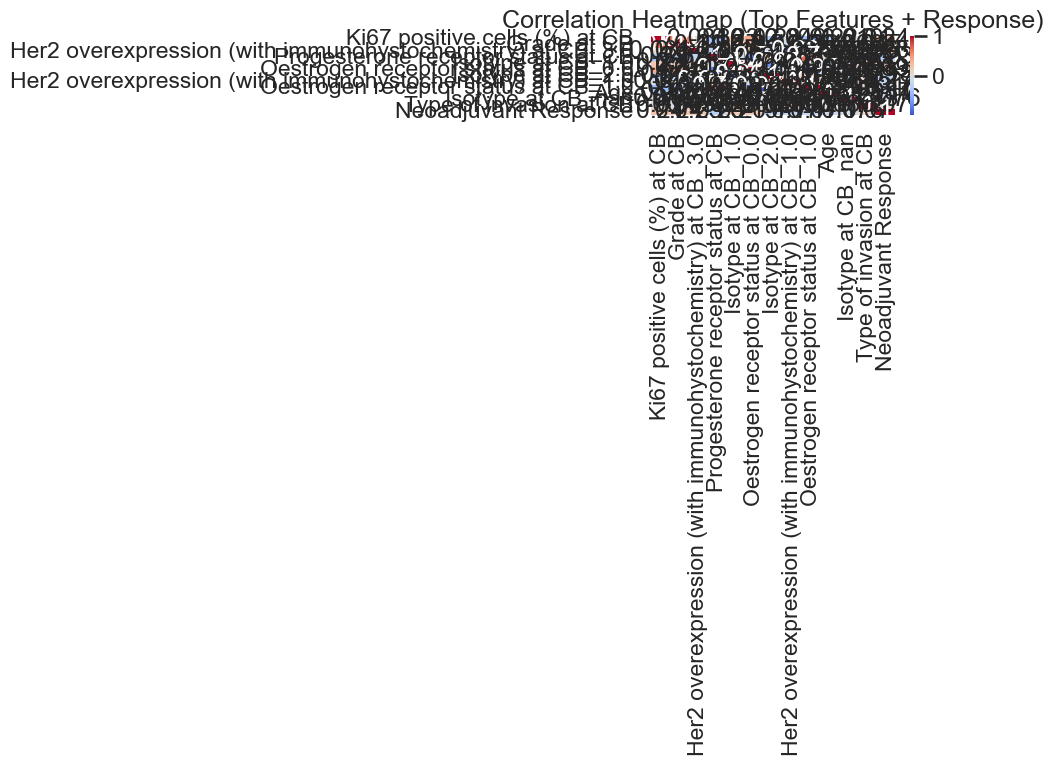

In [21]:
# Correlation with response (point-biserial equivalent via Pearson for binary target)
corr_target = df[numeric_cols + [target_col]].corr(numeric_only=True)[target_col].drop(target_col).sort_values(key=np.abs, ascending=False)

display(corr_target.head(15).rename('corr_with_response').to_frame())

top_for_heatmap = corr_target.head(12).index.tolist()
if len(top_for_heatmap) >= 2:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[top_for_heatmap + [target_col]].corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
    plt.title('Correlation Heatmap (Top Features + Response)')
    plt.tight_layout()
    plt.show()

In [22]:
# Prepare matrix for unsupervised analysis
X = df[feature_cols].copy()
X = X.fillna(X.median(numeric_only=True))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Matrix ready for unsupervised analysis:', X_scaled.shape)

Matrix ready for unsupervised analysis: (1430, 26)


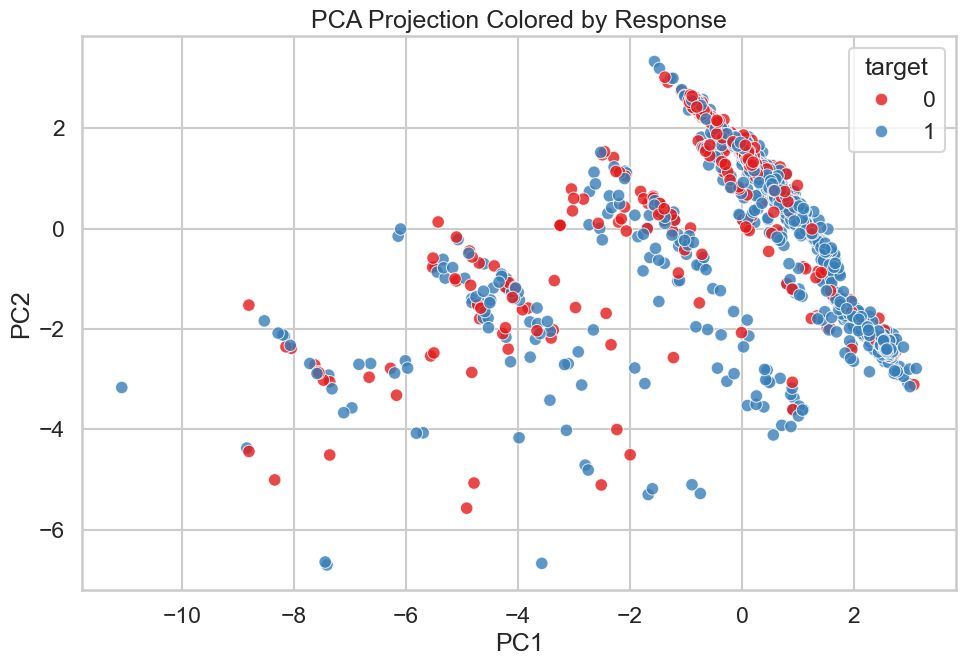

Explained variance ratio: [0.1641 0.1171]
Cumulative explained variance: 0.2813


In [23]:
# PCA for latent structure visualization
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'target': df[target_col].values
})

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='target', palette='Set1', alpha=0.8)
plt.title('PCA Projection Colored by Response')
plt.tight_layout()
plt.show()

print('Explained variance ratio:', pca.explained_variance_ratio_.round(4))
print('Cumulative explained variance:', pca.explained_variance_ratio_.sum().round(4))

,k,silhouette
0,2,0.154470
1,3,0.188291
2,4,0.164245
3,5,0.168990
4,6,0.157998


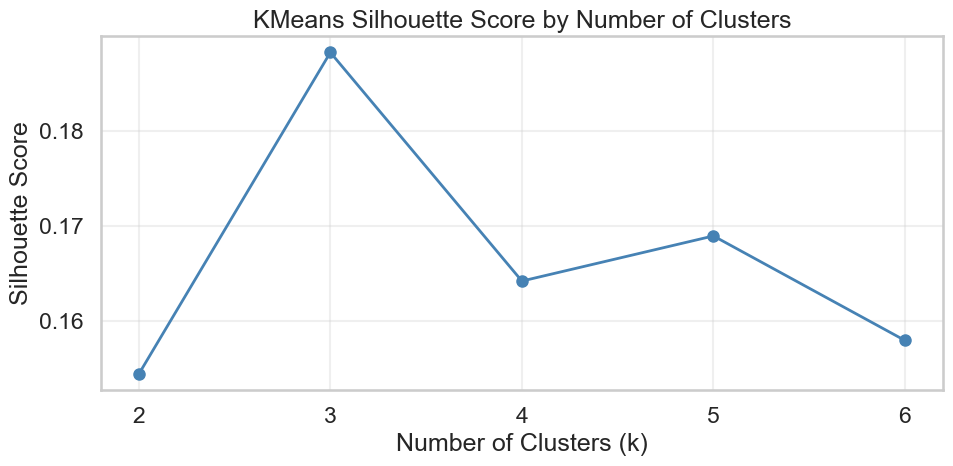

Best k by silhouette: 3


In [24]:
# KMeans model selection by silhouette
k_values = range(2, 7)
sil_scores = []
models = {}

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init='auto')
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    models[k] = (km, labels)

sil_df = pd.DataFrame({'k': list(k_values), 'silhouette': sil_scores})
display(sil_df)

# Plot silhouette scores
plt.figure(figsize=(10, 5))
plt.plot(sil_df['k'], sil_df['silhouette'], marker='o', linewidth=2, markersize=8, color='steelblue')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('KMeans Silhouette Score by Number of Clusters')
plt.grid(True, alpha=0.3)
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

best_k = sil_df.loc[sil_df['silhouette'].idxmax(), 'k']
best_k = int(best_k)
best_km, best_labels = models[best_k]

print(f'Best k by silhouette: {best_k}')

Response proportion inside each cluster:


Neoadjuvant Response,0,1
cluster,,
0,0.140,0.860
1,0.406,0.594
2,0.343,0.657


Adjusted Mutual Information (cluster vs response): 0.0289


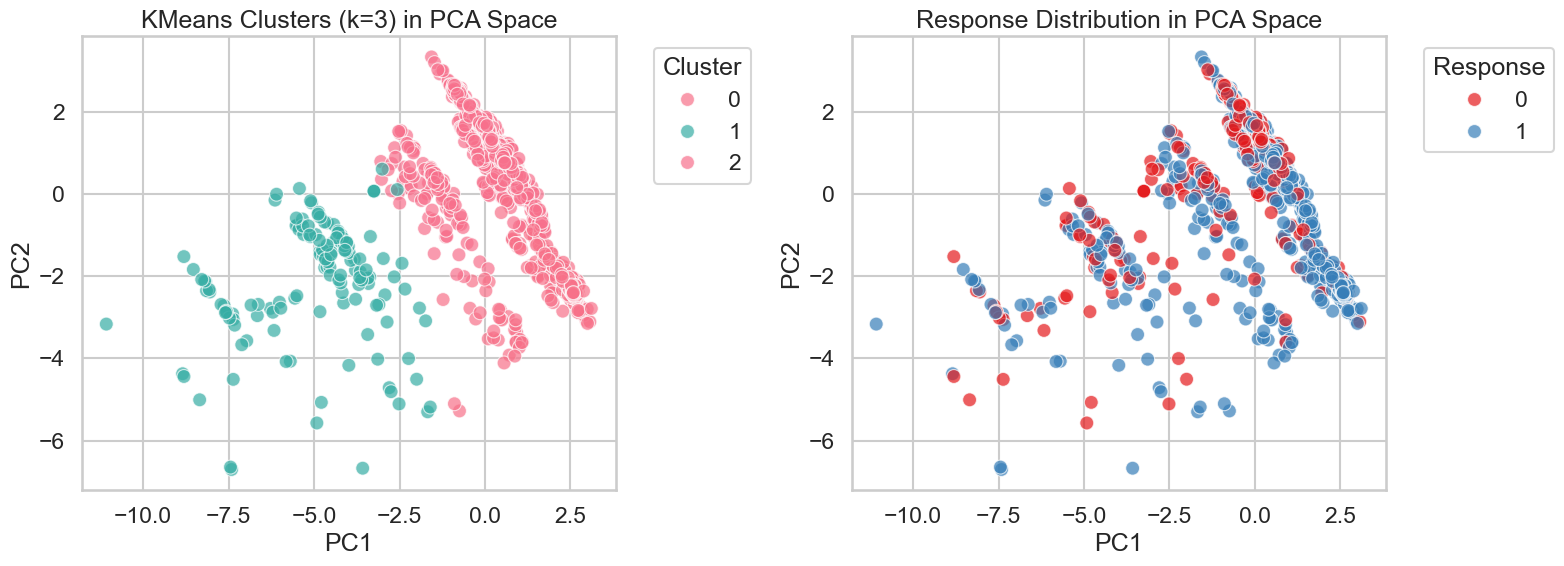

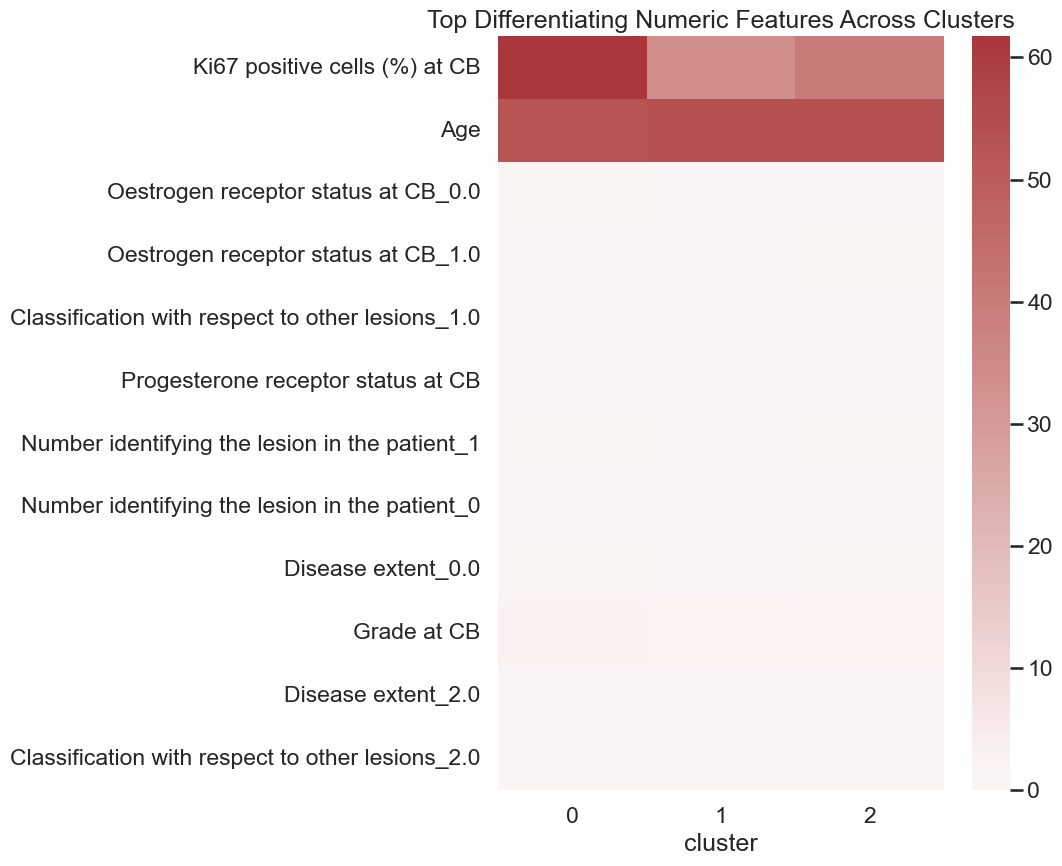

In [25]:
# Cluster interpretation and relation with response
cluster_df = df.copy()
cluster_df['cluster'] = best_labels

ct = pd.crosstab(cluster_df['cluster'], cluster_df[target_col], normalize='index').round(3)
print('Response proportion inside each cluster:')
display(ct)

ami = adjusted_mutual_info_score(cluster_df[target_col], cluster_df['cluster'])
print(f'Adjusted Mutual Information (cluster vs response): {ami:.4f}')

# Visualize clusters in PCA space
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA colored by cluster
pca_for_cluster = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_cluster = pca_for_cluster.fit_transform(X_scaled)

cluster_viz = pd.DataFrame({'PC1': X_pca_cluster[:, 0], 'PC2': X_pca_cluster[:, 1], 'cluster': best_labels})
sns.scatterplot(data=cluster_viz, x='PC1', y='PC2', hue='cluster', palette='husl', ax=axes[0], s=100, alpha=0.7)
axes[0].set_title(f'KMeans Clusters (k={best_k}) in PCA Space')
axes[0].legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

# PCA colored by response
response_viz = pd.DataFrame({'PC1': X_pca_cluster[:, 0], 'PC2': X_pca_cluster[:, 1], 'response': cluster_df[target_col].values})
sns.scatterplot(data=response_viz, x='PC1', y='PC2', hue='response', palette='Set1', ax=axes[1], s=100, alpha=0.7)
axes[1].set_title('Response Distribution in PCA Space')
axes[1].legend(title='Response', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Cluster profile using feature means
cluster_profile = cluster_df.groupby('cluster')[numeric_cols].mean().T

top_var = cluster_profile.var(axis=1).sort_values(ascending=False).head(12).index
plt.figure(figsize=(11, 9))
sns.heatmap(cluster_profile.loc[top_var], cmap='vlag', center=0, annot=False)
plt.title('Top Differentiating Numeric Features Across Clusters')
plt.tight_layout()
plt.show()

In [ ]:
# Agglomerative clustering (consistency check)
agg = AgglomerativeClustering(n_clusters=best_k)
agg_labels = agg.fit_predict(X_scaled)

agg_ami = adjusted_mutual_info_score(df[target_col], agg_labels)
agg_sil = silhouette_score(X_scaled, agg_labels)

print(f'Agglomerative silhouette: {agg_sil:.4f}')
print(f'Agglomerative AMI with response: {agg_ami:.4f}')

# Compare KMeans vs Agglomerative
comparison_data = pd.DataFrame({
    'Method': ['KMeans', 'Agglomerative'],
    'Silhouette Score': [silhouette_score(X_scaled, best_labels), agg_sil],
    'AMI with Response': [ami, agg_ami]
})
display(comparison_data)

# Visualize both clustering methods in PCA space
pca_comp = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_comp = pca_comp.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# KMeans
kmeans_viz = pd.DataFrame({'PC1': X_pca_comp[:, 0], 'PC2': X_pca_comp[:, 1], 'cluster': best_labels})
sns.scatterplot(data=kmeans_viz, x='PC1', y='PC2', hue='cluster', palette='husl', ax=axes[0], s=100, alpha=0.7)
axes[0].set_title(f'KMeans Clustering (k={best_k})')
axes[0].legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

# Agglomerative
agg_viz = pd.DataFrame({'PC1': X_pca_comp[:, 0], 'PC2': X_pca_comp[:, 1], 'cluster': agg_labels})
sns.scatterplot(data=agg_viz, x='PC1', y='PC2', hue='cluster', palette='husl', ax=axes[1], s=100, alpha=0.7)
axes[1].set_title(f'Agglomerative Clustering (k={best_k})')
axes[1].legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Agglomerative silhouette: 0.1405
Agglomerative AMI with response: 0.0256


## Hypothesis checklist for next models

Rough notes for turning the above into actual modeling decisions, once everything above has run.

**Feature-level.** Which variables separate responders from non-responders the most, and does that look like a linear relationship or something curvier?

**Subgroups.** Do the clusters differ meaningfully in responder proportion? Worth checking whether any biomarker/staging pattern concentrates in the high-response clusters specifically.

**Modeling implications.** If the cluster structure holds up, worth trying interaction terms or mixture-like models. If correlations look weak but the subgroup effect is real, lean non-linear (tree ensembles, kernels) over linear. If the class imbalance turns out bad, that needs a weighted loss or some rebalancing at training time.

**Validation.** Still need to check all of this survives repeated CV plus subgroup-aware calibration checks.

Features with LOWEST variance within clusters (high similarity):


,avg_within_cluster_var
Isotype at CB_3.0,0.0023
Isotype at CB_nan,0.0165
Type of invasion at CB,0.0279
Oestrogen receptor status at CB_0.0,0.0296
Disease extent_1.0,0.0349
Oestrogen receptor status at CB_1.0,0.0428
Classification with respect to other lesions_1.0,0.0642
Number identifying the lesion in the patient_0,0.0724
Number identifying the lesion in the patient_1,0.0724
Isotype at CB_2.0,0.0790



Features with HIGHEST variance within clusters (low similarity):


,avg_within_cluster_var
Classification with respect to other lesions_3.0,0.1269
Her2 overexpression (with immunohystochemistry) at CB_3.0,0.1479
Isotype at CB_1.0,0.1664
Her2 overexpression (with immunohystochemistry) at CB_1.0,0.2334
Source of referral,0.2385
Side location of the lesion,0.2508
Grade at CB,0.2743
N (Regional nodes affected),0.4554
Age,162.3426
Ki67 positive cells (%) at CB,409.3232


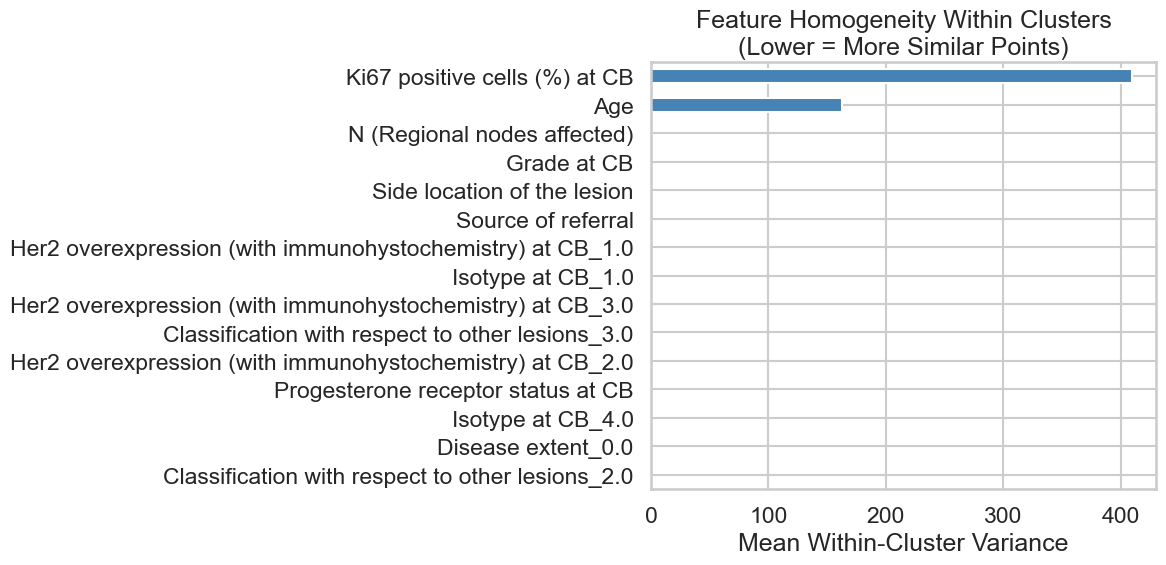

In [26]:
# what actually makes points similar within a cluster
from scipy.stats import f_oneway

# low-variance features are basically what holds the cluster together
within_cluster_var = cluster_df.groupby('cluster')[numeric_cols].var().mean(axis=0).sort_values()

print('Features with LOWEST variance within clusters (high similarity):')
display(within_cluster_var.head(10).to_frame('avg_within_cluster_var').round(4))

print('\nFeatures with HIGHEST variance within clusters (low similarity):')
display(within_cluster_var.tail(10).to_frame('avg_within_cluster_var').round(4))

# Visualize within-cluster homogeneity
fig, ax = plt.subplots(figsize=(12, 6))
within_cluster_var.sort_values().tail(15).plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Mean Within-Cluster Variance')
ax.set_title('Feature Homogeneity Within Clusters\n(Lower = More Similar Points)')
plt.tight_layout()
plt.show()


Top Features That DIFFERENTIATE Clusters (high F-statistic):


,feature,F_statistic,p_value
8,Oestrogen receptor status at CB_0.0,14016.4033,0.0
9,Oestrogen receptor status at CB_1.0,6071.8313,0.0
13,Number identifying the lesion in the patient_0,1398.4600,0.0
14,Number identifying the lesion in the patient_1,1398.4600,0.0
6,Progesterone receptor status at CB,800.3482,0.0
15,Classification with respect to other lesions_1.0,676.8309,0.0
25,Disease extent_2.0,476.4110,0.0
23,Disease extent_0.0,474.9677,0.0
16,Classification with respect to other lesions_2.0,394.0368,0.0
1,Ki67 positive cells (%) at CB,162.8878,0.0


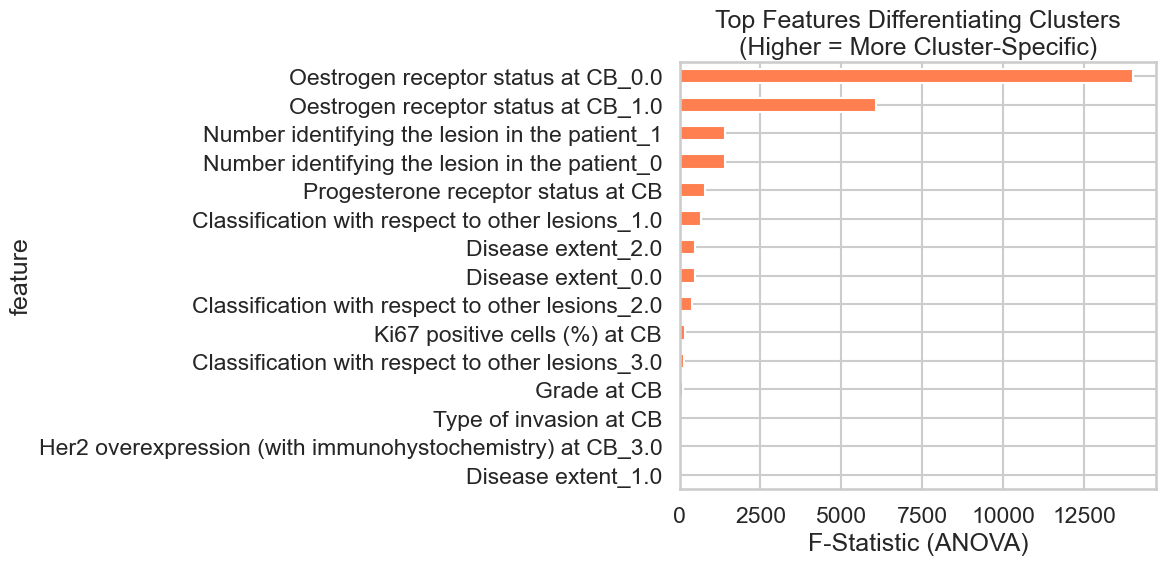

In [27]:
# which features actually separate the clusters, not just correlate with response
from scipy.stats import kruskal

# ANOVA F-statistic to identify differentiating features
anova_results = []

for col in numeric_cols:
    cluster_groups = [cluster_df[cluster_df['cluster'] == c][col].dropna().values for c in range(best_k)]
    if all(len(g) > 1 for g in cluster_groups):
        f_stat, p_value = f_oneway(*cluster_groups)
        anova_results.append({'feature': col, 'F_statistic': f_stat, 'p_value': p_value})

anova_df = pd.DataFrame(anova_results).sort_values('F_statistic', ascending=False)

print('Top Features That DIFFERENTIATE Clusters (high F-statistic):')
display(anova_df.head(15).round(4))

# Visualize differentiating power
fig, ax = plt.subplots(figsize=(12, 6))
anova_df.head(15).set_index('feature')['F_statistic'].sort_values().plot(kind='barh', ax=ax, color='coral')
ax.set_xlabel('F-Statistic (ANOVA)')
ax.set_title('Top Features Differentiating Clusters\n(Higher = More Cluster-Specific)')
plt.tight_layout()
plt.show()


Cluster Profiles:
  Cluster 0: N=329, Response Rate=86.02%
  Cluster 1: N=143, Response Rate=59.44%
  Cluster 2: N=958, Response Rate=65.66%


Detailed Feature Profiles Across Clusters:

Oestrogen receptor status at CB_0.0:


,mean,std,count
cluster,,,
0,1.000,0.000,329
1,0.098,0.298,143
2,0.000,0.000,958



Oestrogen receptor status at CB_1.0:


,mean,std,count
cluster,,,
0,0.000,0.000,329
1,0.867,0.341,143
2,0.987,0.111,958



Number identifying the lesion in the patient_0:


,mean,std,count
cluster,,,
0,0.000,0.000,329
1,0.685,0.466,143
2,0.000,0.000,958



Number identifying the lesion in the patient_1:


,mean,std,count
cluster,,,
0,1.000,0.000,329
1,0.315,0.466,143
2,1.000,0.000,958



Progesterone receptor status at CB:


,mean,std,count
cluster,,,
0,0.043,0.202,329
1,0.832,0.375,143
2,0.859,0.348,958


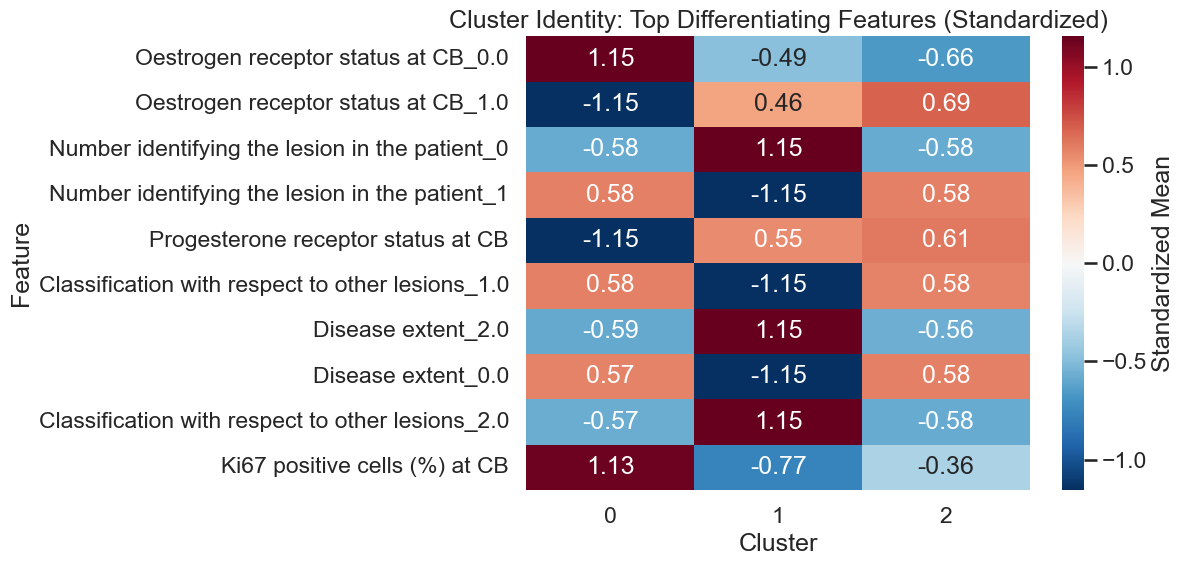

In [28]:
# what characterizes each cluster
top_differentiating = anova_df.head(10)['feature'].tolist()

cluster_profiles = {}
for c in range(best_k):
    cluster_profiles[c] = {
        'size': len(cluster_df[cluster_df['cluster'] == c]),
        'response_rate': cluster_df[cluster_df['cluster'] == c][target_col].mean()
    }

print('Cluster Profiles:')
for c, profile in cluster_profiles.items():
    print(f"  Cluster {c}: N={profile['size']}, Response Rate={profile['response_rate']:.2%}")

# Create detailed feature profiles for top differentiating features
print('\n\nDetailed Feature Profiles Across Clusters:')
print('=' * 80)

feature_profiles = cluster_df.groupby('cluster')[top_differentiating].agg(['mean', 'std'])

for fe in top_differentiating[:5]:  # Show top 5
    print(f"\n{fe}:")
    temp = pd.DataFrame({
        'mean': cluster_df.groupby('cluster')[fe].mean(),
        'std': cluster_df.groupby('cluster')[fe].std(),
        'count': cluster_df.groupby('cluster')[fe].count()
    }).round(3)
    display(temp)

# Heatmap of standardized cluster means (shows cluster identity clearly)
cluster_means = cluster_df.groupby('cluster')[top_differentiating].mean()
cluster_means_scaled = (cluster_means - cluster_means.mean()) / cluster_means.std()

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_means_scaled.T, annot=True, fmt='.2f', cmap='RdBu_r', center=0, 
            cbar_kws={'label': 'Standardized Mean'})
plt.title('Cluster Identity: Top Differentiating Features (Standardized)')
plt.xlabel('Cluster')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [33]:
# how tight vs loose is each cluster
from scipy.spatial.distance import cdist

# Calculate cluster cohesion (average distance from points to their cluster centroid)
cohesion_scores = []

for c in range(best_k):
    cluster_mask = cluster_df['cluster'] == c
    cluster_points = X_scaled[cluster_mask.values]
    cluster_center = cluster_points.mean(axis=0)
    
    distances = np.linalg.norm(cluster_points - cluster_center, axis=1)
    cohesion = distances.mean()
    cohesion_scores.append({
        'cluster': c,
        'avg_distance_to_center': cohesion,
        'size': len(cluster_points),
        'silhouette_score': silhouette_score(X_scaled[cluster_mask.values], np.zeros(len(cluster_points)))
    })

cohesion_df = pd.DataFrame(cohesion_scores).sort_values('avg_distance_to_center')

print('Cluster Cohesion (how tightly grouped):')
display(cohesion_df.round(4))

# Coefficient of variation for features (shows stability/consistency within clusters)
print('\n\nFeature Consistency Within Clusters (Coefficient of Variation):')
cv_within = (cluster_df.groupby('cluster')[numeric_cols].std() / cluster_df.groupby('cluster')[numeric_cols].mean().abs()).mean()
cv_sorted = cv_within.sort_values()

print('Most CONSISTENT features within clusters (low CV = high similarity):')
display(cv_sorted.head(10).rename('avg_CV').to_frame().round(3))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Cluster cohesion
cohesion_df.set_index('cluster')['avg_distance_to_center'].plot(
    kind='bar', ax=axes[0], color='skyblue', edgecolor='black'
)
axes[0].set_ylabel('Avg Distance to Cluster Center')
axes[0].set_title('Cluster Cohesion\n(Lower = Tighter/More Similar Points)')
axes[0].set_xlabel('Cluster')

# Feature consistency
cv_sorted.head(12).plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_xlabel('Coefficient of Variation')
axes[1].set_title('Most Consistent Features Within Clusters')

plt.tight_layout()
plt.show()


ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)

## Reading the cluster similarity output

Quick reference for what each of the four analyses above is actually saying.

The within-cluster variance table: low-variance features are what actually holds a cluster together, its members agree on those. High-variance features barely matter for the cluster's identity.

The ANOVA F-statistics are the flip side: a big F-stat means the feature swings a lot *between* clusters, so it's a decent candidate for describing what makes a cluster distinct from the others.

The standardized heatmap is basically each cluster's fingerprint: dark red means that cluster trends high on the feature, dark blue means it trends low. Good for answering "what do these patients have in common."

Cohesion is about how tight the clusters actually are - low avg. distance to centroid means a genuinely homogeneous group, high distance means a looser, more heterogeneous bucket. The low-CV ("consistent") features are the ones worth trusting as reliable markers of cluster membership.

Practically: stick to the consistent features for a stable model, prioritize clusters with clearly different response rates for subgroup analysis, and treat any low-cohesion cluster as a candidate for further splitting rather than a real homogeneous group.